# Activity 1: Dataset Preparation
## Student Performance (Mathematics) — UCI Machine Learning Repository

**Unit:** Unit I – Foundations & Data Preparation  
**Objective:** Inspect, clean, explore, encode and scale a tabular dataset. No prediction model is trained.

### Dataset information
- **Dataset:** Student Performance — Mathematics (`student-mat.csv`)
- **Source:** UCI Machine Learning Repository, Dataset 320
- **Source page:** https://archive.ics.uci.edu/dataset/320/student+performance
- **Download used below:** public CSV mirror of the UCI mathematics file
- **Expected raw shape:** 395 rows × 33 columns
- **File type:** CSV (semicolon-separated)


The data describes secondary-school students in Portugal. Columns cover school, demographics, family background, study habits, absences and mathematics grades. `G3` is the final mathematics grade (0–20) and could be a target in a later prediction task.



## 1. Import libraries and load the dataset

In [11]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# Public CSV mirror of the UCI Mathematics dataset (semicolon-separated)
DATA_URL = "https://huggingface.co/datasets/DElmazi/Student_Performance/resolve/main/student-mat.csv"
df_original = pd.read_csv(DATA_URL, sep=";")

print("Dataset loaded successfully.")
print("Dataset name: Student Performance (Mathematics)")
print("Source: UCI Machine Learning Repository, Dataset 320")
print("File type: CSV")
print("Rows:", df_original.shape[0])
print("Columns:", df_original.shape[1])

Dataset loaded successfully.
Dataset name: Student Performance (Mathematics)
Source: UCI Machine Learning Repository, Dataset 320
File type: CSV
Rows: 395
Columns: 33


## 2. Load and inspect the dataset

In [12]:
print("First five rows:")
display(df_original.head())

print("Last five rows:")
display(df_original.tail())

print("Shape:", df_original.shape)
print("\\nColumn names:")
print(df_original.columns.tolist())

print("\\nData types:")
display(df_original.dtypes.rename("data_type").to_frame())

print("\\nDataset information:")
df_original.info()

First five rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


Last five rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
390,MS,M,20,U,LE3,A,2,2,services,services,course,other,1,2,2,no,yes,yes,no,yes,yes,no,no,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,course,mother,2,1,0,no,no,no,no,no,yes,yes,no,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,course,other,1,1,3,no,no,no,no,no,yes,no,no,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,course,mother,3,1,0,no,no,no,no,no,yes,yes,no,4,4,1,3,4,5,0,11,12,10
394,MS,M,19,U,LE3,T,1,1,other,at_home,course,father,1,1,0,no,no,no,no,yes,yes,yes,no,3,2,3,3,3,5,5,8,9,9


Shape: (395, 33)
\nColumn names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
\nData types:


,data_type
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object


\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null   

### What the dataset represents
Each row represents one student enrolled in the mathematics course. Examples:
- `school`, `sex`, `address`: school and demographic information.
- `Medu`, `Fedu`, `Mjob`, `Fjob`: parents' education and occupations.
- `studytime`, `failures`, `absences`: academic habits and attendance.
- `G1`, `G2`, `G3`: first-period, second-period and final mathematics grades.

## 3. Identify data types and basic statistics

In [13]:
numeric_cols = df_original.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_original.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:", numeric_cols)
print("\\nCategorical columns:", categorical_cols)

print("\\nNumerical summary:")
display(df_original[numeric_cols].describe().T)

print("\\nCategorical summary:")
display(df_original[categorical_cols].describe().T)

target_col = "G3"
print(f"Potential future target: {target_col} (final mathematics grade, 0–20).")
print("No prediction model is trained in this activity.")

Numerical columns: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
\nCategorical columns: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
\nNumerical summary:


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


\nCategorical summary:


,count,unique,top,freq
school,395,2,GP,349
sex,395,2,F,208
address,395,2,U,307
famsize,395,2,GT3,281
Pstatus,395,2,T,354
Mjob,395,5,other,141
Fjob,395,5,other,217
reason,395,4,course,145
guardian,395,3,mother,273
schoolsup,395,2,no,344


Potential future target: G3 (final mathematics grade, 0–20).
No prediction model is trained in this activity.


## 4. Identify missing values

In [14]:
missing_count = df_original.isna().sum()
missing_percent = (missing_count / len(df_original) * 100).round(2)
missing_report = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
}).sort_values("missing_count", ascending=False)

display(missing_report)
print("Total missing cells:", int(missing_count.sum()))

,missing_count,missing_percent
school,0,0.0
sex,0,0.0
age,0,0.0
address,0,0.0
famsize,0,0.0
Pstatus,0,0.0
Medu,0,0.0
Fedu,0,0.0
Mjob,0,0.0
Fjob,0,0.0


Total missing cells: 0


### Missing-value findings and decision
The UCI metadata indicates that no attributes are missing, and the loaded file is checked again above. If the output confirms zero missing cells, no imputation is required. Mean/median/mode filling is deliberately not applied because it would change valid observations without a reason.

## 5. Make a working copy and handle missing values

In [15]:
# Preserve the original dataset and clean a separate copy.
df = df_original.copy(deep=True)

# Apply imputations only if missing values are actually present.
# Numeric columns: median; categorical columns: mode.
for col in df.columns:
    if df[col].isna().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            mode_values = df[col].mode(dropna=True)
            if not mode_values.empty:
                df[col] = df[col].fillna(mode_values.iloc[0])

print("Missing cells after handling:", int(df.isna().sum().sum()))

Missing cells after handling: 0


## 6. Check duplicate records and consistency

In [16]:
duplicate_count = int(df.duplicated().sum())
print("Exact duplicate rows:", duplicate_count)

# Remove only exact duplicate rows, if any are found.
df = df.drop_duplicates().copy()

# Trim leading/trailing spaces from text categories.
text_cols = df.select_dtypes(include=["object", "category"]).columns
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()

print("Duplicate rows after removal:", int(df.duplicated().sum()))
print("Shape after duplicate check:", df.shape)

# Inspect distinct labels to detect spelling/case inconsistencies.
for col in text_cols:
    print(f"\\n{col}: {sorted(df[col].dropna().unique().tolist())}")

# Check plausible ranges without deleting unusual observations automatically.
range_checks = {
    "age": (15, 22),
    "G1": (0, 20),
    "G2": (0, 20),
    "G3": (0, 20),
    "absences": (0, 93)
}
for col, (low, high) in range_checks.items():
    if col in df.columns:
        bad = df.loc[~df[col].between(low, high), col]
        print(f"{col}: outside expected range = {len(bad)}")

Exact duplicate rows: 0
Duplicate rows after removal: 0
Shape after duplicate check: (395, 33)
\nschool: ['GP', 'MS']
\nsex: ['F', 'M']
\naddress: ['R', 'U']
\nfamsize: ['GT3', 'LE3']
\nPstatus: ['A', 'T']
\nMjob: ['at_home', 'health', 'other', 'services', 'teacher']
\nFjob: ['at_home', 'health', 'other', 'services', 'teacher']
\nreason: ['course', 'home', 'other', 'reputation']
\nguardian: ['father', 'mother', 'other']
\nschoolsup: ['no', 'yes']
\nfamsup: ['no', 'yes']
\npaid: ['no', 'yes']
\nactivities: ['no', 'yes']
\nnursery: ['no', 'yes']
\nhigher: ['no', 'yes']
\ninternet: ['no', 'yes']
\nromantic: ['no', 'yes']
age: outside expected range = 0
G1: outside expected range = 0
G2: outside expected range = 0
G3: outside expected range = 0
absences: outside expected range = 0


### Data-quality decisions
- Exact duplicate rows are counted and removed only if present.
- Text labels are stripped of accidental leading/trailing spaces.
- Grade and age ranges are checked against the dataset description.
- Unusual attendance values are inspected rather than automatically deleted; high absences may be genuine observations.

## 7. Basic exploratory data analysis (EDA)

Numerical summary statistics:


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


School frequency:


,count
school,
GP,349
MS,46


Gender frequency:


,count
sex,
F,208
M,187


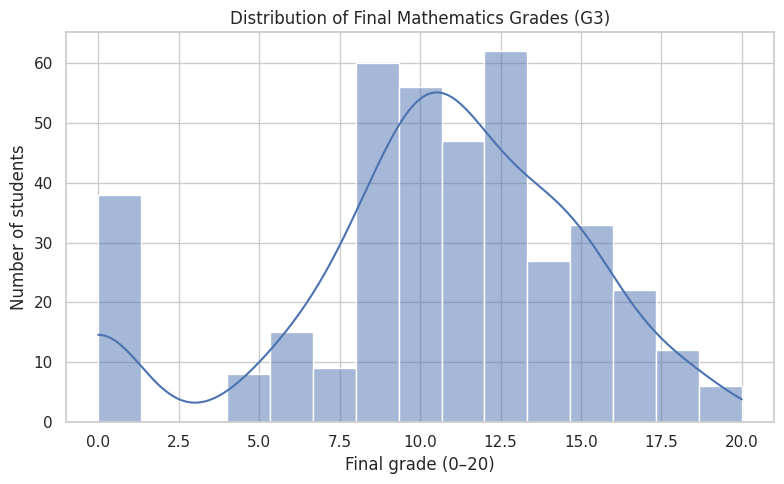

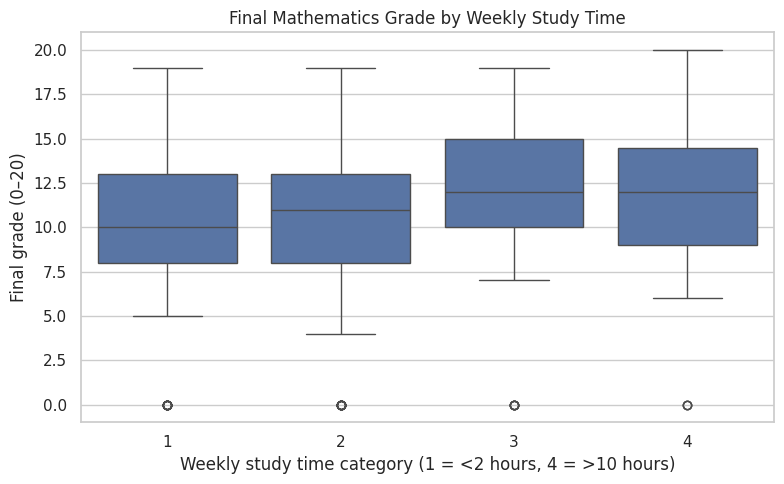

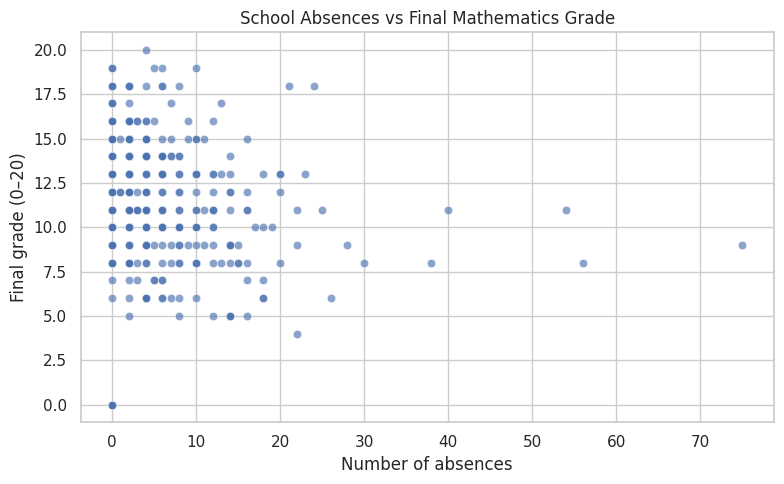

Mean final grade: 10.42
Median final grade: 11.0
Most frequent study-time category: 2


In [17]:
print("Numerical summary statistics:")
display(df.select_dtypes(include=np.number).describe().T)

# Frequency counts for at least one categorical column
print("School frequency:")
display(df["school"].value_counts(dropna=False).to_frame("count"))

print("Gender frequency:")
display(df["sex"].value_counts(dropna=False).to_frame("count"))

# Visualisation 1: distribution of final mathematics grade
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="G3", bins=15, kde=True)
plt.title("Distribution of Final Mathematics Grades (G3)")
plt.xlabel("Final grade (0–20)")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

# Visualisation 2: study time versus final grade
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("Final Mathematics Grade by Weekly Study Time")
plt.xlabel("Weekly study time category (1 = <2 hours, 4 = >10 hours)")
plt.ylabel("Final grade (0–20)")
plt.tight_layout()
plt.show()

# Optional third visualisation: absences and final grade
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="absences", y="G3", alpha=0.65)
plt.title("School Absences vs Final Mathematics Grade")
plt.xlabel("Number of absences")
plt.ylabel("Final grade (0–20)")
plt.tight_layout()
plt.show()

print("Mean final grade:", round(df["G3"].mean(), 2))
print("Median final grade:", round(df["G3"].median(), 2))
print("Most frequent study-time category:", int(df["studytime"].mode().iloc[0]))

### EDA observations
Use the charts and printed statistics above to write observations from the actual output. Typical questions to address:
1. Is the final-grade distribution concentrated around the middle of the 0–20 scale, or is it skewed?
2. Do grade medians differ across study-time categories?
3. Are there students with unusually high absences, and do those points appear to have a wide range of grades?

Do not claim that one factor causes another; these are descriptive patterns only.

## 8. Encode categorical features

In [18]:
# Nominal text columns are represented with one-hot encoding.
categorical_cols = df.select_dtypes(include=["object", "category", "string"]).columns.tolist()
print("Categorical columns to encode:", categorical_cols)

df_encoded = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=False,
    dtype=int
)

print("Shape before encoding:", df.shape)
print("Shape after one-hot encoding:", df_encoded.shape)
display(df_encoded.head())

Categorical columns to encode: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Shape before encoding: (395, 33)
Shape after one-hot encoding: (395, 59)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,...,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other,schoolsup_no,schoolsup_yes,famsup_no,famsup_yes,paid_no,paid_yes,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,1,3,6,5,6,6,1,0,1,0,0,1,1,0,1,...,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,1,1,0,1,0
1,17,1,1,1,2,0,5,3,3,1,1,3,4,5,5,6,1,0,1,0,0,1,1,0,0,...,0,0,1,0,0,0,1,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,3,3,10,7,8,10,1,0,1,0,0,1,0,1,0,...,0,0,0,0,1,0,0,1,0,0,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0
3,15,4,2,1,3,0,3,2,2,1,1,5,2,15,14,15,1,0,1,0,0,1,1,0,0,...,1,0,0,1,0,0,0,1,0,1,0,0,1,0,1,0,1,0,1,0,1,0,1,0,1
4,16,3,3,1,2,0,4,3,2,1,2,5,4,6,10,10,1,0,1,0,0,1,1,0,0,...,0,0,0,1,0,0,1,0,0,1,0,0,1,0,1,1,0,0,1,0,1,1,0,1,0


### Encoding explanation
Nominal categories such as school, sex, address, parental occupation and yes/no responses do not have a meaningful numeric order. One-hot encoding creates a separate 0/1 indicator column for each category. Existing ordered numeric scales (for example study-time categories) are retained as numeric values because their codes have an intended order.

## 9. Scale numerical features where appropriate

In [19]:
# Keep the final grade as a possible target; do not scale it as an input feature.
# Identifier columns, if present, would also be excluded from scaling.
target_col = "G3"
numeric_feature_cols = [
    col for col in df_encoded.select_dtypes(include=np.number).columns
    if col != target_col and col.lower() not in {"id", "student_id"}
]

scaler = StandardScaler()
df_prepared = df_encoded.copy()
df_prepared[numeric_feature_cols] = scaler.fit_transform(df_prepared[numeric_feature_cols])

print("Scaling method: StandardScaler (z-score standardisation)")
print("Number of scaled numeric feature columns:", len(numeric_feature_cols))
print("Target column left unscaled:", target_col)
display(df_prepared.head())

Scaling method: StandardScaler (z-score standardisation)
Number of scaled numeric feature columns: 58
Target column left unscaled: G3


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,...,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other,schoolsup_no,schoolsup_yes,famsup_no,famsup_yes,paid_no,paid_yes,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,1.023046,1.143856,1.360371,0.792251,-0.042286,-0.449944,0.062194,-0.236010,0.801479,-0.540699,-1.003789,-0.399289,0.036424,-1.782467,-1.254791,6,0.36305,-0.36305,0.948176,-0.948176,-0.535392,0.535392,0.636941,-0.636941,2.938392,...,-0.625176,3.552561,1.313064,-0.617348,-0.316668,-0.601722,-0.543214,0.668496,-0.296908,-2.597133,2.597133,1.257656,-1.257656,0.919671,-0.919671,1.017881,-1.017881,-0.507899,0.507899,-0.23094,0.23094,2.232677,-2.232677,0.708450,-0.708450
1,0.238380,-1.600009,-1.399970,-0.643249,-0.042286,-0.449944,1.178860,-0.236010,-0.097908,-0.540699,-1.003789,-0.399289,-0.213796,-1.782467,-1.520979,6,0.36305,-0.36305,0.948176,-0.948176,-0.535392,0.535392,0.636941,-0.636941,-0.340322,...,-0.625176,-0.281487,1.313064,-0.617348,-0.316668,-0.601722,1.840894,-1.495896,-0.296908,0.385040,-0.385040,-0.795130,0.795130,0.919671,-0.919671,1.017881,-1.017881,1.968894,-1.968894,-0.23094,0.23094,-0.447893,0.447893,0.708450,-0.708450
2,-1.330954,-1.600009,-1.399970,-0.643249,-0.042286,3.589323,0.062194,-0.236010,-0.997295,0.583385,0.551100,-0.399289,0.536865,-1.179147,-0.722415,10,0.36305,-0.36305,0.948176,-0.948176,-0.535392,0.535392,-1.570004,1.570004,-0.340322,...,-0.625176,-0.281487,-0.761577,-0.617348,3.157883,-0.601722,-0.543214,0.668496,-0.296908,-2.597133,2.597133,1.257656,-1.257656,-1.087346,1.087346,1.017881,-1.017881,-0.507899,0.507899,-0.23094,0.23094,-0.447893,0.447893,0.708450,-0.708450
3,-1.330954,1.143856,-0.479857,-0.643249,1.150779,-0.449944,-1.054472,-1.238419,-0.997295,-0.540699,-1.003789,1.041070,-0.464016,1.234133,0.874715,15,0.36305,-0.36305,0.948176,-0.948176,-0.535392,0.535392,0.636941,-0.636941,-0.340322,...,1.599549,-0.281487,-0.761577,1.619831,-0.316668,-0.601722,-0.543214,0.668496,-0.296908,0.385040,-0.385040,-0.795130,0.795130,-1.087346,1.087346,-0.982433,0.982433,-0.507899,0.507899,-0.23094,0.23094,-0.447893,0.447893,-1.411533,1.411533
4,-0.546287,0.229234,0.440257,-0.643249,-0.042286,-0.449944,0.062194,-0.236010,-0.997295,-0.540699,-0.226345,1.041070,-0.213796,-1.480807,-0.190038,10,0.36305,-0.36305,0.948176,-0.948176,-0.535392,0.535392,0.636941,-0.636941,-0.340322,...,-0.625176,-0.281487,-0.761577,1.619831,-0.316668,-0.601722,1.840894,-1.495896,-0.296908,0.385040,-0.385040,-0.795130,0.795130,-1.087346,1.087346,1.017881,-1.017881,-0.507899,0.507899,-0.23094,0.23094,2.232677,-2.232677,0.708450,-0.708450


### Scaling explanation
Standardisation transforms each selected numerical input feature to approximately mean 0 and standard deviation 1. This can help distance-based and gradient-based algorithms when variables use different scales. The target `G3` is not scaled. In a real predictive workflow, fit the scaler on training data only and apply the learned transformation to validation/test data to avoid data leakage. Here, the full-data fit is used only to demonstrate preparation because no model is trained.

## 10. Verify and save the prepared dataset

In [20]:
print("Final shape:", df_prepared.shape)
print("Remaining missing cells:", int(df_prepared.isna().sum().sum()))
print("Remaining duplicate rows:", int(df_prepared.duplicated().sum()))

# Save separately; original data remains unchanged.
output_file = "student_performance_prepared.csv"
df_prepared.to_csv(output_file, index=False)

print(f"Prepared dataset saved as: {output_file}")
display(df_prepared.head())

# Optional: download in Google Colab
try:
    from google.colab import files
    files.download(output_file)
except Exception:
    print("If not using Colab, find the CSV in the notebook working directory.")

Final shape: (395, 59)
Remaining missing cells: 0
Remaining duplicate rows: 0
Prepared dataset saved as: student_performance_prepared.csv


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,...,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other,schoolsup_no,schoolsup_yes,famsup_no,famsup_yes,paid_no,paid_yes,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,1.023046,1.143856,1.360371,0.792251,-0.042286,-0.449944,0.062194,-0.236010,0.801479,-0.540699,-1.003789,-0.399289,0.036424,-1.782467,-1.254791,6,0.36305,-0.36305,0.948176,-0.948176,-0.535392,0.535392,0.636941,-0.636941,2.938392,...,-0.625176,3.552561,1.313064,-0.617348,-0.316668,-0.601722,-0.543214,0.668496,-0.296908,-2.597133,2.597133,1.257656,-1.257656,0.919671,-0.919671,1.017881,-1.017881,-0.507899,0.507899,-0.23094,0.23094,2.232677,-2.232677,0.708450,-0.708450
1,0.238380,-1.600009,-1.399970,-0.643249,-0.042286,-0.449944,1.178860,-0.236010,-0.097908,-0.540699,-1.003789,-0.399289,-0.213796,-1.782467,-1.520979,6,0.36305,-0.36305,0.948176,-0.948176,-0.535392,0.535392,0.636941,-0.636941,-0.340322,...,-0.625176,-0.281487,1.313064,-0.617348,-0.316668,-0.601722,1.840894,-1.495896,-0.296908,0.385040,-0.385040,-0.795130,0.795130,0.919671,-0.919671,1.017881,-1.017881,1.968894,-1.968894,-0.23094,0.23094,-0.447893,0.447893,0.708450,-0.708450
2,-1.330954,-1.600009,-1.399970,-0.643249,-0.042286,3.589323,0.062194,-0.236010,-0.997295,0.583385,0.551100,-0.399289,0.536865,-1.179147,-0.722415,10,0.36305,-0.36305,0.948176,-0.948176,-0.535392,0.535392,-1.570004,1.570004,-0.340322,...,-0.625176,-0.281487,-0.761577,-0.617348,3.157883,-0.601722,-0.543214,0.668496,-0.296908,-2.597133,2.597133,1.257656,-1.257656,-1.087346,1.087346,1.017881,-1.017881,-0.507899,0.507899,-0.23094,0.23094,-0.447893,0.447893,0.708450,-0.708450
3,-1.330954,1.143856,-0.479857,-0.643249,1.150779,-0.449944,-1.054472,-1.238419,-0.997295,-0.540699,-1.003789,1.041070,-0.464016,1.234133,0.874715,15,0.36305,-0.36305,0.948176,-0.948176,-0.535392,0.535392,0.636941,-0.636941,-0.340322,...,1.599549,-0.281487,-0.761577,1.619831,-0.316668,-0.601722,-0.543214,0.668496,-0.296908,0.385040,-0.385040,-0.795130,0.795130,-1.087346,1.087346,-0.982433,0.982433,-0.507899,0.507899,-0.23094,0.23094,-0.447893,0.447893,-1.411533,1.411533
4,-0.546287,0.229234,0.440257,-0.643249,-0.042286,-0.449944,0.062194,-0.236010,-0.997295,-0.540699,-0.226345,1.041070,-0.213796,-1.480807,-0.190038,10,0.36305,-0.36305,0.948176,-0.948176,-0.535392,0.535392,0.636941,-0.636941,-0.340322,...,-0.625176,-0.281487,-0.761577,1.619831,-0.316668,-0.601722,1.840894,-1.495896,-0.296908,0.385040,-0.385040,-0.795130,0.795130,-1.087346,1.087346,1.017881,-1.017881,-0.507899,0.507899,-0.23094,0.23094,2.232677,-2.232677,0.708450,-0.708450


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
This activity used the UCI Student Performance Mathematics dataset to practise a complete basic data-preparation workflow. The dataset was loaded and inspected, numerical and categorical columns were identified, summary statistics and frequency counts were reviewed, and EDA visualisations were created. Missing values and duplicate rows were checked before any cleaning decisions. Text categories were standardised by trimming whitespace, nominal features were one-hot encoded, and numerical input features were standardised while the final grade target was retained unchanged. The prepared dataset was saved as a separate CSV file. No prediction model was built.

